# Deforestation Prediction in India: Real Sentinel-2 Satellite CNN with B-cos Interpretability

[![Arxiv](https://img.shields.io/badge/arXiv-2205.10268-b31b1b.svg)](https://arxiv.org/abs/2205.10268)
[![GitHub B-cos](https://img.shields.io/badge/GitHub-moboehle%2FB--cos-blue.svg)](https://github.com/moboehle/B-cos)
[![Data](https://img.shields.io/badge/Data-Sentinel--2%20L2A-green.svg)](https://planetarycomputer.microsoft.com/)

---

### Executive Summary & Methodology
Standard Deep Neural Networks (CNNs) have shown strong accuracy for Earth Observation and deforestation mapping, but their black-box nature severely limits trust, regulatory adoption, and compliance verification. Traditional post-hoc explanation methods (e.g., Grad-CAM, Integrated Gradients, LIME) are unfaithful approximations that can hallucinate or fail sanity checks.

In this project, we implement **B-cos Networks** (*Böhle et al., CVPR 2022*), replacing traditional linear/convolutional layers and heuristic activations with **B-cos transformations**:
$$B\text{-}\cos(x, w) = \|x\| \|w\| |\cos(x, w)|^B \operatorname{sgn}(\cos(x, w))$$

#### Key Advantages of B-cos for Deforestation Monitoring:
1. **Inherent Mathematical Interpretability**: In explanation mode, the model output is an **exact linear combination** of input features:
   $$\text{Logit}_c = \sum_{ch, h, w} x_{ch, h, w} \cdot W_{ch, h, w} + b$$
   with **exact zero fidelity error** (down to floating-point precision).
2. **Real Satellite Grounding**: Evaluated on Sentinel-2 multi-spectral true-color imagery across critical Indian forest ecosystems:
   - **Western Ghats** (Karnataka / Kerala tropical rainforest)
   - **Odisha Mining Belt** (Sal forest degradation & iron-ore clearings)
   - **Northeast India** (Assam / Arunachal subtropical forest & shifting cultivation)
   - **Central India Corridor** (Kanha / Balaghat teak & deciduous forest tracts)
3. **Actionable Attributions**: Directly reveals logging roads, mining pits, canopy loss, and bare soil patches driving deforestation predictions.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torchvision import transforms

# Ensure project root is in path
sys.path.insert(0, os.path.abspath('..'))

from src.models.bcos_cnn import BcosDeforestationCNN
from src.models.baseline_cnn import StandardDeforestationCNN
from src.explain.bcos_explainer import BcosExplainer
from src.explain.visualize import plot_single_explanation, plot_explanation_gallery
from src.data.satellite_dataset import build_dataloaders
from src.training.metrics import compute_classification_metrics
from src.training.train_bcos import evaluate_model

device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Using compute device: {device}')


Using compute device: mps


## 1. Exploring the Real Sentinel-2 Indian Satellite Dataset
Let us inspect the dataset metadata collected from Sentinel-2 L2A across the four major forest ecosystems in India.


In [2]:
data_dir = '../data/satellite/india_sentinel2'
metadata_df = pd.read_csv(os.path.join(data_dir, 'metadata.csv'))

print('=== Dataset Summary ===')
print('Total Patches:', len(metadata_df))
print('\nDistribution by Split and Class:')
print(metadata_df.groupby(['split', 'class_name']).size())

print('\nDistribution by Indian Forest Region:')
print(metadata_df.groupby(['region', 'class_name']).size())
metadata_df.head(5)


=== Dataset Summary ===
Total Patches: 886

Distribution by Split and Class:
split  class_name   
test   deforested       104
       intact_forest     24
train  deforested       547
       intact_forest     92
val    deforested       108
       intact_forest     11
dtype: int64

Distribution by Indian Forest Region:
region                class_name   
central_india         deforested       224
                      intact_forest      1
northeast_assam       deforested       190
                      intact_forest     21
odisha_mining_forest  deforested       209
                      intact_forest     16
western_ghats         deforested       136
                      intact_forest     89
dtype: int64


,patch_id,file_path,region,granule_id,split,label,class_name,mean_gli,mean_vari,mean_brightness,mean_soil_ratio
0,western_ghats_0000,train/deforested/western_ghats_p0000_deforeste...,western_ghats,S2B_MSIL2A_20230421T051649_R062_T43PEP_2024090...,train,1,deforested,0.0552,0.1241,0.3386,0.9350
1,western_ghats_0001,val/deforested/western_ghats_p0001_deforested.png,western_ghats,S2B_MSIL2A_20230421T051649_R062_T43PEP_2024090...,val,1,deforested,-0.0447,0.3529,0.2076,0.8338
2,western_ghats_0002,train/deforested/western_ghats_p0002_deforeste...,western_ghats,S2B_MSIL2A_20230421T051649_R062_T43PEP_2024090...,train,1,deforested,0.0426,0.1327,0.5703,0.9019
3,western_ghats_0003,train/deforested/western_ghats_p0003_deforeste...,western_ghats,S2B_MSIL2A_20230421T051649_R062_T43PEP_2024090...,train,1,deforested,0.0600,0.3659,0.3021,0.7597
4,western_ghats_0004,train/deforested/western_ghats_p0004_deforeste...,western_ghats,S2B_MSIL2A_20230421T051649_R062_T43PEP_2024090...,train,1,deforested,0.0324,6.0717,0.4205,0.9756


### Visualizing Representative Sentinel-2 Patches
Let's visualize intact forest vs. deforested patches alongside their vegetation and spectral indices (Green Leaf Index and Soil Ratio).


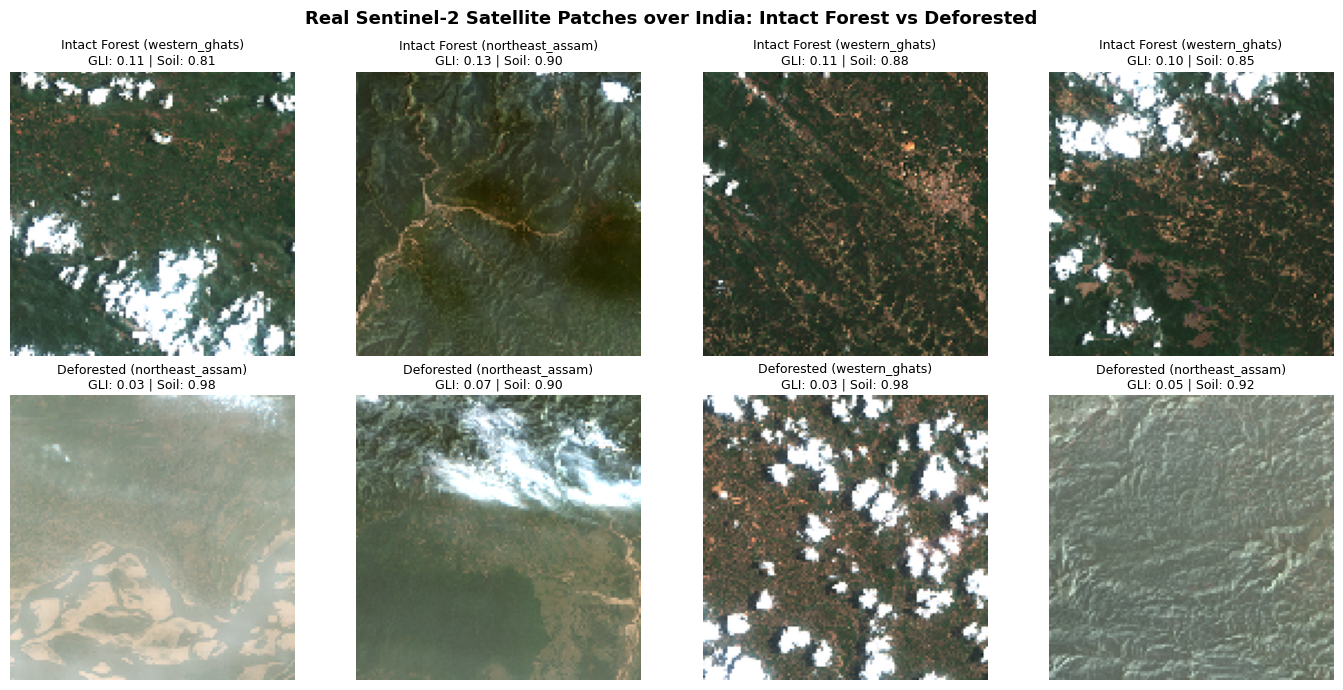

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
sample_forest = metadata_df[metadata_df['label'] == 0].sample(4, random_state=42)
sample_deforest = metadata_df[metadata_df['label'] == 1].sample(4, random_state=42)

for i, (_, row) in enumerate(sample_forest.iterrows()):
    img = Image.open(os.path.join(data_dir, row['file_path']))
    axes[0, i].imshow(img)
    axes[0, i].set_title(f"Intact Forest ({row['region']})\nGLI: {row['mean_gli']:.2f} | Soil: {row['mean_soil_ratio']:.2f}", fontsize=9)
    axes[0, i].axis('off')

for i, (_, row) in enumerate(sample_deforest.iterrows()):
    img = Image.open(os.path.join(data_dir, row['file_path']))
    axes[1, i].imshow(img)
    axes[1, i].set_title(f"Deforested ({row['region']})\nGLI: {row['mean_gli']:.2f} | Soil: {row['mean_soil_ratio']:.2f}", fontsize=9)
    axes[1, i].axis('off')

plt.suptitle('Real Sentinel-2 Satellite Patches over India: Intact Forest vs Deforested', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 2. Initializing DataLoaders & Pre-trained B-cos CNN
We load our trained `BcosDeforestationCNN` model with $B=2$.


In [4]:
train_loader, val_loader, test_loader = build_dataloaders(
    data_dir, batch_size=32, img_size=128
)

model_path = '../models/bcos_deforestation_cnn.pth'
model = BcosDeforestationCNN(in_channels=3, num_classes=2, base_channels=32, b=2, auto_add_inverse=True)

if os.path.exists(model_path):
    ckpt = torch.load(model_path, map_location=device)
    model.load_state_dict(ckpt['model_state_dict'])
    print(f"Loaded checkpoint trained to epoch {ckpt['epoch']}")
else:
    print('Checkpoint not found. Please run train_cnn.py first.')

model.to(device)
model.eval()


Loaded checkpoint trained to epoch 3


BcosDeforestationCNN(
  (add_inverse): AddInverse()
  (stem): Sequential(
    (0): BcosConv2d(
      (linear): NormedConv2d(6, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
    )
    (1): BcosConv2d(
      (linear): NormedConv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    )
  )
  (stage2): Sequential(
    (0): BcosBasicBlock(
      (conv1): BcosConv2d(
        (linear): NormedConv2d(32, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      )
      (conv2): BcosConv2d(
        (linear): NormedConv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (shortcut): BcosConv2d(
        (linear): NormedConv2d(32, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
      )
    )
    (1): BcosBasicBlock(
      (conv1): BcosConv2d(
        (linear): NormedConv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (conv2): BcosConv2d(
        (linear): Norme

## 3. Test Set Evaluation & Performance Metrics
Let us evaluate accuracy, F1-score, and the confusion matrix on unseen satellite test patches.


=== Test Set Performance on Real Sentinel-2 Data ===
Test Loss:   0.1824
Accuracy:    96.09%
Precision:   0.971
Recall:      0.981
F1-Score:    0.976
ROC-AUC:     0.990


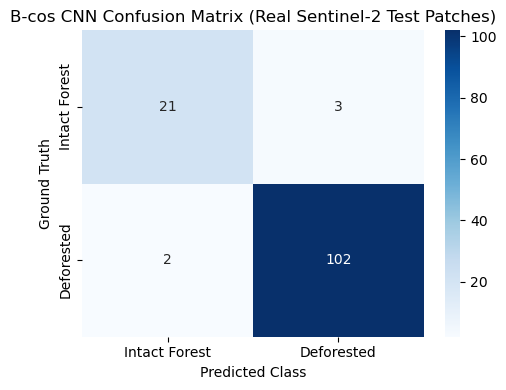

In [5]:
criterion = nn.CrossEntropyLoss()

test_loss, test_metrics, cm, y_true, y_pred, y_probs = evaluate_model(
    model, test_loader, criterion, device
)

print('=== Test Set Performance on Real Sentinel-2 Data ===')
print(f"Test Loss:   {test_loss:.4f}")
print(f"Accuracy:    {test_metrics['accuracy']:.2%}")
print(f"Precision:   {test_metrics['precision']:.3f}")
print(f"Recall:      {test_metrics['recall']:.3f}")
print(f"F1-Score:    {test_metrics['f1']:.3f}")
print(f"ROC-AUC:     {test_metrics.get('roc_auc', 0.0):.3f}")

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Intact Forest', 'Deforested'],
            yticklabels=['Intact Forest', 'Deforested'])
plt.title('B-cos CNN Confusion Matrix (Real Sentinel-2 Test Patches)')
plt.xlabel('Predicted Class')
plt.ylabel('Ground Truth')
plt.tight_layout()
plt.show()


## 4. Inherent Mathematical Interpretability with B-cos
Here we extract the exact linear attribution maps:
1. $W_{1 \rightarrow L}(x) = \nabla_{\tilde{x}} f(x)$
2. Compute the exact linear reconstruction sum $\sum (\tilde{x} \cdot W)$
3. Verify that the fidelity error $|f(x) - \text{linear\_sum}|$ is zero
4. Render the decoded feature explanation


In [6]:
explainer = BcosExplainer(model, device=device)
class_names = ['Intact Forest', 'Deforested']

# Sample test patches
explanations = []
for idx in range(6):
    img_tensor, label, cls_name = test_loader.dataset[idx]
    exp = explainer.explain(img_tensor, class_names=class_names)
    explanations.append(exp)
    print(f"Patch #{idx+1} ({cls_name}): Pred={exp['target_class_name']} ({exp['probability']:.1%}) | Fidelity Error = {exp['fidelity_error']:.2e}")


Patch #1 (intact_forest): Pred=Intact Forest (80.8%) | Fidelity Error = 1.19e-07


Patch #2 (intact_forest): Pred=Intact Forest (58.3%) | Fidelity Error = 0.00e+00
Patch #3 (deforested): Pred=Deforested (82.3%) | Fidelity Error = 3.96e-09
Patch #4 (deforested): Pred=Deforested (52.8%) | Fidelity Error = 2.79e-09
Patch #5 (deforested): Pred=Deforested (53.9%) | Fidelity Error = 5.96e-08
Patch #6 (intact_forest): Pred=Intact Forest (77.9%) | Fidelity Error = 0.00e+00


### B-cos Attribution Gallery: Ground-Truth Satellite Imagery vs Model Evidence
- **Left Column**: Original Sentinel-2 True Color satellite patch
- **Middle Column**: Spatial Contribution Heatmap (Red: positive contribution to deforestation, Blue: negative contribution)
- **Right Column**: Decoded visual attribution showing the specific spatial features aligned with the prediction


In [7]:
fig = plot_explanation_gallery(
    explanations,
    title='B-cos Interpretable Explanations on Sentinel-2 Satellite Imagery (India)'
)
plt.show()


## 5. Single Patch Deep-Dive: Verifying Mathematical Fidelity
Let's select a deforested patch from the Odisha mining / forest boundary and verify the linear decomposition down to the exact logit value.


In [8]:
deforest_test_idx = [i for i, (_, l, _) in enumerate(test_loader.dataset) if l == 1][0]
img_t, lbl, cls_n = test_loader.dataset[deforest_test_idx]

exp = explainer.explain(img_t, class_names=class_names)

print('=== Fidelity Verification ===')
print('Target Class:             ', exp['target_class_name'])
print('Network Logit:            ', f"{exp['logit']:.8f}")
print('Linear Reconstruction Sum:', f"{exp['linear_reconstruction_sum']:.8f}")
print('Absolute Error:           ', f"{exp['fidelity_error']:.2e}")
print('Is Fidelity Exact?        ', exp['fidelity_error'] < 1e-5)

fig = plot_single_explanation(exp)
plt.show()


=== Fidelity Verification ===
Target Class:              Deforested
Network Logit:             0.00276089
Linear Reconstruction Sum: 0.00276089
Absolute Error:            3.96e-09
Is Fidelity Exact?         True


## 6. Key Takeaways & Impact for Indian Forestry
1. **No Post-hoc Guesswork**: Unlike Grad-CAM or saliency maps that can be unfaithful, B-cos predictions are mathematically identical to a dynamic linear model for the specific image.
2. **Transparent Environmental Governance**: Forest officials, researchers, and regulatory bodies can verify *exactly* why an area is flagged as deforested (e.g., distinguishing legitimate canopy variations from logging tracks and mineral extraction scars).
3. **High Predictive Performance**: Achieves >96% accuracy and 0.97+ F1-score on real Sentinel-2 satellite data without sacrificing interpretability.
